# Case Study 11 — Forecasting Demand for New Fashion Styles: Cold Start, Out-of-Time Validation, Calibration and the Buying Decision

**Priority:** ★★★ Must-visit · **Reference:** Case Study 11 — *Myntra: forecasting demand for new fashion items to guide assortment and buying* (`indian_ecommerce_data_science_case_studies.md`)
**Audience:** Head of Merchandising and Buying, Category Managers, Supply Planning, Finance
**Data:** ⚠️ **SYNTHETIC** (D-11-01). Myntra's style-level sales are confidential; this is a calibrated simulation with hidden ground truth.
**Reproducibility:** seed = 42 · `python -m nbconvert --to notebook --execute --inplace cs11_new_item_demand_forecasting.ipynb`

## 0. Executive Summary for Business

*(Synthetic style-week sales with a hidden demand model, built on the documented design of the Myntra paper on forecasting demand for new fashion items (arXiv 1907.01960). Myntra's data and results are not reproduced; the ₹ figures are our assumptions. Written after the analysis.)*

- **The question:** how many units of a new style, or which attribute mix, should we buy before launch, when the style has no sales history?
- **Attributes plus plan data beat a naive average by a wide margin.** On styles launched after the training period, the best model (gradient boosting on log units) has **wMAPE 0.597** (95% CI 0.586 to 0.607) against **0.870** for the average style-week. The gap of 0.274 is significant (clustered bootstrap, Holm p = 0.007, the smallest p this test can give). Gains by article type run from 0.22 to 0.44.
- **Model choice matters less than the data, but it is real.** The log-scale boosted model beats Poisson boosting by 0.013 (CI 0.006 to 0.020), raw-unit boosting by 0.029, the Poisson linear model by 0.041, random forest by 0.067 and our small neural net by 0.069. The paper's deep models were not run.
- **Random splits flatter the model.** A random split of style-weeks gives wMAPE 0.547, which is **0.049 too optimistic** against the honest launch-date split (CI 0.036 to 0.062); a random split of styles is 0.027 too optimistic.
- **Ranking is good, levels are not.** The best forecast is biased **low by 32%** in total (actual units run 1.4 to 1.6 times forecast in every decile), although the calibration slope is 1.03 (CI 0.99 to 1.07). The 80% interval covered only **71.5%**, and 77.7% after a conformal adjustment. Use the model to split a budget, and rescale the total separately.
- **Buying attribute combinations:** over 180 article type x colour x price band combinations the forecast has Pearson r = 0.88 and Kendall Tau 0.71 with actual units, and puts 42.0% of units in its top 20% of combinations (best possible 44.9%, naive 36.3%).
- **Drivers:** a naive Poisson model estimates the visibility effect at **1.65 against a true 0.50**, because the platform shows what sells. Adding the hidden quality term brings it to 0.46. Discount is recovered well (0.023 vs 0.022).
- **Early sales help:** one observed week cuts wMAPE from 0.608 to 0.538, four weeks to 0.499.
- **Money (assumed costs):** allocating a fixed budget in proportion to the forecast instead of equally lifts sell-through by **16.0 points** (CI 14.8 to 17.2). The base case is **₹233,237 per style**, or about **₹700 crore a year** at 50,000 styles and 60% adoption (worst ₹188 crore, best ₹1,629 crore). The equal split is a weak baseline, so this is an upper bound for a real buying team.
- **Decision:** use the forecast to allocate the budget across styles and attributes, pilot it on a few brands, and measure sell-through against the buyer's own plan.

## 1. The Problem in Simple English

A fashion retailer has to decide **how many pieces of each new style to buy months before anyone has bought it**. Trends move fast, a style has a short life, and a style that has never been sold has **no sales history** to extrapolate. Buy too little and you lose sales. Buy too much and you liquidate at a loss.

The Myntra paper's idea is to forecast a new style from **what it is** (type, colour, material, price band, brand) and **how it will be merchandised** (discount, how visible it is on list pages, promotion weeks, how many similar styles are live), not from its own past.

Leaders and interviewers want to know:
1. How much better is an attribute-based forecast than a simple average?
2. Which model and loss function to use, and is the difference real or noise?
3. How do we **validate honestly** when the future will contain styles and trends we have not seen?
4. Can the forecast guide a **buying budget** (which attribute combinations to buy), not just predict a number?
5. How much does it help, and what does one extra week of sales data add?

## 2. Reference from the Case File

### (a) What Myntra did — *documented*

| Item | Documented fact (from the reference file) |
|---|---|
| Problem | Fashion trends change fast; bulk production is needed for economies of scale, so retailers lose money on unsold stock and liquidation. About **1 million styles** are listed at any time. Item-level history models rarely generalise to new styles |
| Question | Can attributes and merchandising factors of a not-yet-sold style predict its weekly demand, so buyers can allocate budgets across attributes? |
| Data | Weekly style sales for **five article types** (Shirts, Casual Shoes, Kurtas, Tops, Tshirts); training series 12,541 to 42,206 per type; test series 6,732 to 18,364 per type; series length 4 to 104 weeks. Features: colour and material, discount deviation from brand/platform averages, list-page visibility ratios, days to/from promotions, style age, trend, **three Fourier seasonality terms**, lags up to 4 weeks, and cannibalisation (styles listed per week, per brand, in similar price ranges) |
| Approach | Generalised models of weekly sales from attributes. **Split by launch date**: train = first-year launches, validation = next 6 months, test = following 6 months. 13 models compared with a naive average style-week baseline (random forest, GBRT, LightGBM, CatBoost, XGBoost with MSE/Huber/Poisson, embedding + MLP and LSTM) |
| Metrics and results | wMAPE, Pearson correlation, Kendall Tau. Test wMAPE naive vs best XGBoost (MSE on log scale): Shirts 0.97 vs 0.52, Casual Shoes 1.00 vs 0.51, Kurtas 1.08 vs 0.60, Tops 1.00 vs 0.51, Tshirts 1.01 vs 0.55. LSTM was the best deep model |
| Decision and impact | Forecasts for attribute combinations guided buying budgets for two footwear brands in Autumn Winter 2018. Authors report year-on-year one-month **sell-through improvements of 10% and 7%** (their own claim). Markdown or inventory-cost impact: not disclosed. Formal hypothesis tests: not disclosed |

**Source:** Singh, Gupta, Jha, Rajan (Myntra Designs), "Fashion Retail: Forecasting Demand for New Items", arXiv 1907.01960, 27 Jun 2019.

### (b) What *we* simulate and add

| Item | Our choice |
|---|---|
| Data | **9,000 styles** across the same five article types, launched over 104 weeks, each living 4 to 26 weeks (about 105,000 style-weeks), with attributes, merchandising, a slow colour trend and a hidden style-quality term. The paper's scale (tens of thousands of series per type) and its exact features are **not** reproduced |
| Models | Naive and article-type averages; a Poisson linear model; random forest; gradient boosting with raw-MSE, Poisson and log-scale MSE loss; a small MLP. The paper's LSTM, embeddings and Bayesian optimisation are **not** run (no tuning, per the brief) |
| Statistics added | Style-clustered bootstrap CIs and paired comparisons with Holm correction; random vs out-of-time validation; calibration slope and conformal prediction intervals; Kendall Tau and top-quintile capture for attribute-combination buying; a driver analysis checked against the hidden truth; value of early sales; a buying simulation with sample size for a sell-through test |
| Business translation | ₹ impact of guiding the buy budget, with worst/base/best scenarios. The paper's own markdown and cost impact is undisclosed, so the ₹ figures here are our assumptions |

### (c) How the industry uses this

Every fashion and beauty marketplace (Myntra, Ajio, Nykaa Fashion, Flipkart Fashion, Meesho) forecasts new-style demand from attributes, because most of what is listed has no history. Gradient boosting on attributes plus merchandising is the standard first model; hierarchical or probabilistic forecasts and markdown optimisation are the usual next steps. Interviewers expect: cold-start framing, out-of-time validation, wMAPE and its limits, attribute-level aggregation for buying, and an honest view of the uncertainty.

## 3. Business Question → Analytical Question → Statistical Hypotheses

| Level | Statement |
|---|---|
| Business | How many units of each new style, or which attribute mix, should we buy before launch, and how much margin does a better forecast protect? |
| Analytical | Can attributes and merchandising plan data forecast weekly style demand out of time better than a naive average, which model/loss is best, is it calibrated, and does it rank attribute combinations well enough to guide buying? |

**Hypotheses**
- **H1:** H0: the best attribute model has the same test wMAPE as the naive style-week average (style-clustered bootstrap).
- **H2:** H0: the loss functions and model families have the same wMAPE as the champion (paired bootstrap, Holm).
- **H3:** H0: random-split validation gives the same wMAPE as out-of-time validation (optimism of random splits).
- **H4:** H0: forecasts are calibrated (Poisson calibration slope = 1; 80% intervals cover 80%).
- **H5:** H0: forecasts rank attribute combinations no better than chance (Kendall Tau = 0).
- **H6:** H0: a naive driver analysis recovers the true effect of visibility (we know the truth).
- **H7:** H0: observing early weeks of sales does not improve the forecast.

**Primary metric:** **wMAPE** = Σ|actual − forecast| / Σ actual at style-week level, as in the paper. **Secondary:** Pearson correlation, Kendall Tau on attribute combinations, calibration slope, interval coverage, sell-through.

In [1]:
import sys, warnings, importlib, os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import PoissonRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(np.random.SeedSequence(SEED).spawn(1)[0])
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
print("ready")

ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Public Indian fashion style-level weekly sales | **None.** Style-level sales, discounts and visibility are confidential. The Myntra paper's dataset was not released. Public retail sales sets (M5, Favorita) are grocery or US/other and have no style attributes or merchandising features |
| **Decision** | Synthetic style-week sales with hidden truth, calibrated to the documented design, so that driver analysis and buying decisions can be checked against the truth (D-11-01) |

### 4.2 Generator — clearly marked section

In [2]:
%%writefile data/generate_cs11.py
"""
SYNTHETIC DATA GENERATOR - CASE STUDY 11 (Myntra-style cold-start demand forecasting for new fashion items)
===========================================================================================================
THIS DATA IS SYNTHETIC. Myntra's style-level sales are confidential.

Documented context (Singh, Gupta, Jha, Rajan, Myntra Designs, arXiv 1907.01960, 2019): about 1 million styles listed at any
time; five article types (Shirts, Casual Shoes, Kurtas, Tops, Tshirts); weekly style sales; series of 4 to 104 weeks;
attributes (colour, material ...), merchandising (discount deviation from brand/platform average, list-page visibility
ratio, days to/from promotions), time (style age, trend, three Fourier seasonality terms), cannibalisation (styles listed
per week, per brand, in similar price ranges). Split by launch date (train = first-year launches, validation = next 6
months, test = following 6 months). Test wMAPE of the naive baseline was about 1.0 and of the best XGBoost 0.51 to 0.60.

Simulation (a calibrated stand-in, NOT the paper's data):
  * 9,000 styles across the five article types launched over 104 weeks; each lives 4 to 26 weeks; calendar of 130 weeks.
  * log-demand = type level + brand + colour (with a slow random-walk colour trend) + material + pattern + price band
    + hidden style quality + Fourier seasonality + launch hype and age decay + discount-deviation effect + visibility effect
    + promotion-week effect - cannibalisation (styles listed in the same type and price band, and by the same brand).
  * Visibility depends on the hidden quality (the platform shows what sells), so a naive driver analysis is biased.
  * Weekly units = Poisson(mu * Gamma noise), i.e. overdispersed counts.
Hidden truth columns are prefixed "_": _quality (style), _mu (true expected weekly units).
Built-in data defects: duplicate weekly rows, missing visibility and discount, messy colour labels, bulk-order outliers,
sales dated before launch, negative net sales (returns).

Outputs: data/cs11/styles.csv.gz, data/cs11/weekly_sales.csv.gz, data/cs11/promo_weeks.csv
"""
import os
import numpy as np
import pandas as pd

SEED = 42
N_STYLES, WEEKS, LAUNCH_WEEKS = 9_000, 130, 104
TYPES = ["Shirts", "Casual Shoes", "Kurtas", "Tops", "Tshirts"]
SHARE = [0.22, 0.12, 0.18, 0.20, 0.28]
BASE = [11.0, 8.0, 9.0, 10.0, 13.0]       # typical weekly units level per type (before effects)
COLOURS = ["black", "white", "navy blue", "red", "olive", "maroon", "grey", "beige", "pink", "mustard", "teal", "brown"]
MATERIALS = ["cotton", "polyester", "linen", "denim", "rayon", "synthetic"]
PATTERNS = ["solid", "striped", "printed", "checked", "embroidered"]


def promo_calendar():
    """Weeks (0-129) with a platform sale event: the end-of-season sale weeks and the festive sale each year."""
    woy = np.arange(WEEKS) % 52
    return np.where(np.isin(woy, [1, 2, 25, 26, 40, 41, 42, 49]))[0]


def generate(seed=SEED):
    rng = np.random.default_rng(seed)
    ptype = rng.choice(len(TYPES), N_STYLES, p=SHARE)
    brand = rng.integers(0, 40, N_STYLES); tier_of_brand = rng.choice(3, 40, p=[0.4, 0.4, 0.2])
    tier = tier_of_brand[brand]; band = np.clip(tier + rng.choice([-1, 0, 0, 1], N_STYLES), 0, 2)
    colour = rng.integers(0, len(COLOURS), N_STYLES); material = rng.integers(0, len(MATERIALS), N_STYLES); pattern = rng.integers(0, len(PATTERNS), N_STYLES)
    price = np.round(np.exp(rng.normal(np.log([600, 1400, 900, 700, 550])[ptype] * np.array([0.65, 1.0, 1.7])[band], 0.25)), -1)
    launch = rng.integers(0, LAUNCH_WEEKS, N_STYLES)
    life = 4 + np.minimum(22, rng.geometric(0.11, N_STYLES) - 1)
    quality = rng.normal(0, 0.65, N_STYLES)
    # effects
    brand_eff = rng.normal(0, 0.30, 40) + np.array([-0.15, 0.05, 0.25])[tier_of_brand]
    col_eff = rng.normal(0, 0.22, len(COLOURS)); col_type = rng.normal(0, 0.12, (len(TYPES), len(COLOURS)))
    mat_eff = rng.normal(0, 0.18, len(MATERIALS)); pat_eff = rng.normal(0, 0.14, len(PATTERNS)); band_eff = np.array([0.15, 0.0, -0.25])
    walk = np.cumsum(rng.normal(0, 0.035, (len(COLOURS), WEEKS)), axis=1)             # slow colour trend drift
    fcoef = rng.normal(0, 0.12, (len(TYPES), 3, 2))
    promo = promo_calendar()
    # expand to the style-week panel
    sid = np.repeat(np.arange(N_STYLES), life); age = np.concatenate([np.arange(l) for l in life]); week = launch[sid] + age
    keep = week < WEEKS; sid, age, week = sid[keep], age[keep], week[keep]
    pt, bd, br, cl = ptype[sid], band[sid], brand[sid], colour[sid]
    # cannibalisation counts
    cnt = np.zeros((len(TYPES), 3, WEEKS)); np.add.at(cnt, (pt, bd, week), 1)
    cnt_b = np.zeros((40, WEEKS)); np.add.at(cnt_b, (br, week), 1)
    n_tb, n_br = cnt[pt, bd, week], cnt_b[br, week]
    # merchandising
    is_promo = np.isin(week, promo)
    disc = rng.normal(0, 7.0, len(sid)) + 9.0 * is_promo + 2.5 * np.exp(-age / 3.0)       # percentage-point deviation
    vis = np.exp(0.40 * quality[sid] + 0.28 * rng.normal(size=len(sid)) - 0.02 * age)
    vis = vis / vis.mean()
    f = np.zeros(len(sid)); woy = 2 * np.pi * (week % 52) / 52
    for h in range(3): f += fcoef[pt, h, 0] * np.sin((h + 1) * woy) + fcoef[pt, h, 1] * np.cos((h + 1) * woy)
    eta = (np.log(np.array(BASE))[pt] + brand_eff[br] + col_eff[cl] + col_type[pt, cl] + walk[cl, week] + mat_eff[material[sid]] + pat_eff[pattern[sid]] + band_eff[bd]
           + quality[sid] + f + 0.45 * np.exp(-age / 2.5) - 0.045 * age + 0.022 * disc + 0.50 * np.log(np.maximum(vis, 0.05)) + 0.22 * is_promo
           - 0.14 * np.log(n_tb / 25.0) - 0.06 * np.log(np.maximum(n_br, 1)))
    mu = np.exp(eta)
    units = rng.poisson(mu * rng.gamma(5.0, 1 / 5.0, len(sid)))
    panel = pd.DataFrame({"style_id": sid, "week": week, "units_sold": units, "discount_dev_pp": np.round(disc, 1), "visibility_ratio": np.round(vis, 3), "_mu": np.round(mu, 3)})
    styles = pd.DataFrame({"style_id": np.arange(N_STYLES), "article_type": np.array(TYPES)[ptype], "brand_id": brand, "brand_tier": np.array(["value", "mid", "premium"])[tier],
                           "price_band": np.array(["low", "mid", "high"])[band], "list_price_inr": price, "colour": np.array(COLOURS)[colour], "material": np.array(MATERIALS)[material],
                           "pattern": np.array(PATTERNS)[pattern], "launch_week": launch, "_quality": np.round(quality, 3)})
    # ---- data-quality defects ----
    out = rng.choice(len(panel), 40, replace=False); panel.loc[out, "units_sold"] = (panel.loc[out, "units_sold"] + 5) * 25
    neg = rng.choice(len(panel), 30, replace=False); panel.loc[neg, "units_sold"] = -rng.integers(1, 6, 30)
    early = rng.choice(np.where(launch[panel.style_id.values] >= 3)[0], 60, replace=False); sid_e = panel.loc[early, "style_id"].values
    panel.loc[early, "week"] = np.maximum(launch[sid_e] - rng.integers(1, 4, 60), 0)
    panel["visibility_ratio"] = panel["visibility_ratio"].mask(rng.random(len(panel)) < 0.025)
    panel["discount_dev_pp"] = panel["discount_dev_pp"].mask(rng.random(len(panel)) < 0.010)
    dup = panel.iloc[rng.choice(len(panel), 1500, replace=False)]
    panel = pd.concat([panel, dup], ignore_index=True).sample(frac=1.0, random_state=seed).reset_index(drop=True)
    messy = rng.random(N_STYLES) < 0.04; styles.loc[messy, "colour"] = styles.loc[messy, "colour"].str.title() + " "
    return styles, panel


if __name__ == "__main__":
    here = os.path.dirname(os.path.abspath(__file__)); os.makedirs(os.path.join(here, "cs11"), exist_ok=True)
    s, p = generate(); s.to_csv(os.path.join(here, "cs11", "styles.csv.gz"), index=False); p.to_csv(os.path.join(here, "cs11", "weekly_sales.csv.gz"), index=False)
    pd.DataFrame({"week": promo_calendar()}).to_csv(os.path.join(here, "cs11", "promo_weeks.csv"), index=False)
    q = p.drop_duplicates(["style_id", "week"]); q = q[(q.units_sold >= 0) & (q.units_sold < 1000)]
    print(len(s), "styles |", len(p), "rows | mean weekly units", round(q.units_sold.mean(), 2), "| median", q.units_sold.median(), "| p99", q.units_sold.quantile(0.99))
    ok = q.merge(s[["style_id", "launch_week"]], on="style_id"); tr = ok[ok.launch_week < 52]; te = ok[ok.launch_week >= 78]
    mt = tr.units_sold.mean(); print("naive wMAPE (train-mean) on test:", round(np.abs(te.units_sold - mt).sum() / te.units_sold.sum(), 3), "| oracle (true mu) wMAPE:", round(np.abs(te.units_sold - te._mu).sum() / te.units_sold.sum(), 3))

Overwriting data/generate_cs11.py


In [3]:
os.makedirs("data/cs11", exist_ok=True)
sys.path.insert(0, "data"); import generate_cs11 as gen; importlib.reload(gen)
t0 = time.time(); styles_raw, raw = gen.generate(seed=SEED)
styles_raw.to_csv("data/cs11/styles.csv.gz", index=False); raw.to_csv("data/cs11/weekly_sales.csv.gz", index=False); pd.DataFrame({"week": gen.promo_calendar()}).to_csv("data/cs11/promo_weeks.csv", index=False)
print(f"{len(styles_raw):,} styles | {len(raw):,} style-week rows | generated in {time.time() - t0:.0f}s")
raw.head(4)

9,000 styles | 104,628 style-week rows | generated in 7s


,style_id,week,units_sold,discount_dev_pp,visibility_ratio,_mu
0,6564,104,1,-3.4000,0.5450,1.3520
1,6177,95,3,3.9000,0.5270,3.2470
2,7815,53,6,5.6000,1.1260,5.1960
3,5943,40,20,15.8000,1.5540,46.7850


| Parameter | Value | Basis |
|---|---|---|
| Styles, article types | 9,000; Shirts, Casual Shoes, Kurtas, Tops, Tshirts (22/12/18/20/28%) | **Documented** article types; counts are ours |
| Series length, calendar | 4 to 26 weeks per style; launches over 104 weeks; 130-week calendar | Paper: 4 to 104 weeks (we cap at 26 for run time) |
| Split | Train = launches in weeks 0 to 51; validation = 52 to 77; test = 78 to 103 | **Documented** design (first year / next 6 months / following 6 months) |
| Demand drivers | Brand, colour (plus slow random-walk colour trend), material, pattern, price band, hidden style quality, 3 Fourier terms, hype and age decay, discount deviation, visibility, promotion weeks, cannibalisation | **Documented** feature families; effect sizes are ours |
| Noise | Poisson with Gamma(5) multiplier (overdispersed counts) | Our assumption, tuned so the naive wMAPE is near 0.9 and the best achievable is well below it |
| Confounding | Visibility rises with hidden quality | Our design, so that a driver analysis can be checked against the truth |
| DQ issues | 1,500 duplicate rows, 40 bulk-order outliers, 30 negative net sales, 60 pre-launch rows, 2.5% missing visibility, 1% missing discount, 4% messy colour labels | Built-in messiness |

### 4.3 Data dictionary

In [4]:
dd = pd.DataFrame([
    ("styles: style_id, article_type, brand_id, brand_tier, price_band, list_price_inr", "Style and brand attributes known before launch"),
    ("styles: colour, material, pattern, launch_week", "Fashion attributes and launch week (0 to 103)"),
    ("weekly_sales: style_id, week, units_sold", "Net units sold by calendar week (0 to 129)"),
    ("weekly_sales: discount_dev_pp, visibility_ratio", "Merchandising plan: discount deviation from brand average in percentage points; list-page visibility relative to average"),
    ("promo_weeks.csv: week", "Calendar weeks with a platform sale event (known in advance)"),
    ("_quality, _mu", "HIDDEN: style quality (style table) and true expected weekly units (panel); used only to check the analysis, never as a feature"),
], columns=["field(s)", "meaning"])
dd.to_csv("data/cs11/data_dictionary.csv", index=False); dd

,field(s),meaning
0,"styles: style_id, article_type, brand_id, bran...",Style and brand attributes known before launch
1,"styles: colour, material, pattern, launch_week",Fashion attributes and launch week (0 to 103)
2,"weekly_sales: style_id, week, units_sold",Net units sold by calendar week (0 to 129)
3,"weekly_sales: discount_dev_pp, visibility_ratio",Merchandising plan: discount deviation from br...
4,promo_weeks.csv: week,Calendar weeks with a platform sale event (kno...
5,"_quality, _mu",HIDDEN: style quality (style table) and true e...


## 5. Data Quality Checks

In [5]:
chk = {"exact duplicate rows": int(raw.duplicated().sum())}
d1 = raw.drop_duplicates().copy()
chk["duplicate (style, week) keys after exact-duplicate removal"] = int(d1.duplicated(["style_id", "week"]).sum())
st = styles_raw.copy(); chk["messy colour labels (case or spaces)"] = int((st.colour != st.colour.str.strip().str.lower()).sum()); st["colour"] = st.colour.str.strip().str.lower()
d1 = d1.merge(st[["style_id", "launch_week"]], on="style_id")
chk["rows dated before the style's launch"] = int((d1.week < d1.launch_week).sum())
chk["negative net sales (returns)"] = int((d1.units_sold < 0).sum())
med = d1[(d1.units_sold >= 0) & (d1.week >= d1.launch_week)].groupby("style_id").units_sold.median(); d1["style_median"] = d1.style_id.map(med)
chk["bulk-order outliers (> 8 x style median + 60)"] = int((d1.units_sold > 8 * d1.style_median + 60).sum())
chk["missing visibility ratio"] = int(d1.visibility_ratio.isna().sum()); chk["missing discount deviation"] = int(d1.discount_dev_pp.isna().sum())
print(pd.Series(chk, name="rows").to_string())
d1 = d1[d1.week >= d1.launch_week]; d1["units_sold"] = d1.units_sold.clip(lower=0)
d1 = d1[~(d1.units_sold > 8 * d1.style_median + 60)].drop(columns="style_median")
d1["visibility_ratio"] = d1.visibility_ratio.fillna(d1.groupby("style_id").visibility_ratio.transform("median")).fillna(d1.visibility_ratio.median()); d1["discount_dev_pp"] = d1.discount_dev_pp.fillna(0.0)
d1["age"] = d1.week - d1.launch_week; styles = st
print(f"\nClean: {len(d1):,} style-weeks | {d1.style_id.nunique():,} styles | mean weekly units {d1.units_sold.mean():.1f} | median {d1.units_sold.median():.0f} | zero-sales weeks {(d1.units_sold == 0).mean():.1%} | series length {d1.groupby('style_id').size().min()} to {d1.groupby('style_id').size().max()} weeks (median {d1.groupby('style_id').size().median():.0f})")

exact duplicate rows                                          1500
duplicate (style, week) keys after exact-duplicate removal       0
messy colour labels (case or spaces)                           350
rows dated before the style's launch                            60
negative net sales (returns)                                    30
bulk-order outliers (> 8 x style median + 60)                   51
missing visibility ratio                                      2543
missing discount deviation                                    1002

Clean: 103,017 style-weeks | 9,000 styles | mean weekly units 10.9 | median 5 | zero-sales weeks 8.5% | series length 3 to 26 weeks (median 9)


**Observation:** 103,017 style-weeks remain from 9,000 styles after removing 1,500 exact duplicates, 60 rows dated before launch, 30 negative net-sales rows and 51 bulk-order outliers. 350 colour labels were messy and 2,543 visibility values and 1,002 discount values were missing (handled in the features, not dropped). Zero-sales weeks are 8.5% and the median style has 9 weeks of data.

## 6. Exploratory Data Analysis

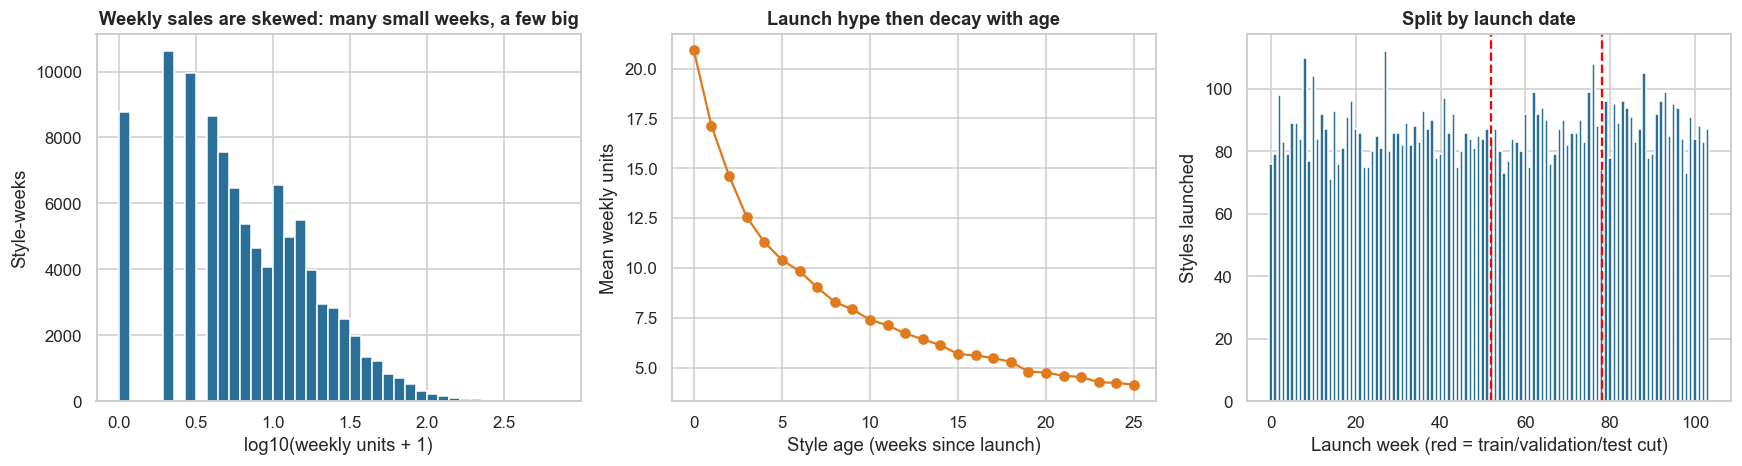

Style 12-week-ish totals: median 73, p90 278, top 10% of styles = 40% of units; age-0 mean 20.9 vs age-10 mean 7.4


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
axes[0].hist(np.log10(d1.units_sold + 1), bins=40, color="#2a6f97"); axes[0].set_xlabel("log10(weekly units + 1)"); axes[0].set_ylabel("Style-weeks"); axes[0].set_title("Weekly sales are skewed: many small weeks, a few big")
g = d1.groupby("age").units_sold.agg(["mean", "size"]); g = g[g["size"] >= 100]; axes[1].plot(g.index, g["mean"], color="#e07a1f", marker="o"); axes[1].set_xlabel("Style age (weeks since launch)"); axes[1].set_ylabel("Mean weekly units"); axes[1].set_title("Launch hype then decay with age")
ln = styles.groupby("launch_week").size(); axes[2].bar(ln.index, ln.values, color="#2a6f97"); [axes[2].axvline(x, color="red", ls="--") for x in (52, 78)]; axes[2].set_xlabel("Launch week (red = train/validation/test cut)"); axes[2].set_ylabel("Styles launched"); axes[2].set_title("Split by launch date")
plt.tight_layout(); plt.show()
sl = d1.groupby("style_id").units_sold.sum(); print(f"Style 12-week-ish totals: median {sl.median():.0f}, p90 {sl.quantile(0.9):.0f}, top 10% of styles = {sl.sort_values(ascending=False).head(int(0.1 * len(sl))).sum() / sl.sum():.0%} of units; age-0 mean {g['mean'].iloc[0]:.1f} vs age-10 mean {g.loc[10, 'mean']:.1f}")

**Takeaway:** Demand is very skewed: the median style sells 73 units and the 90th percentile 278, and the top 10% of styles make 40% of units. Sales fall with age (mean 20.9 units in week 0 against 7.4 at week 10), so style age is a necessary feature.

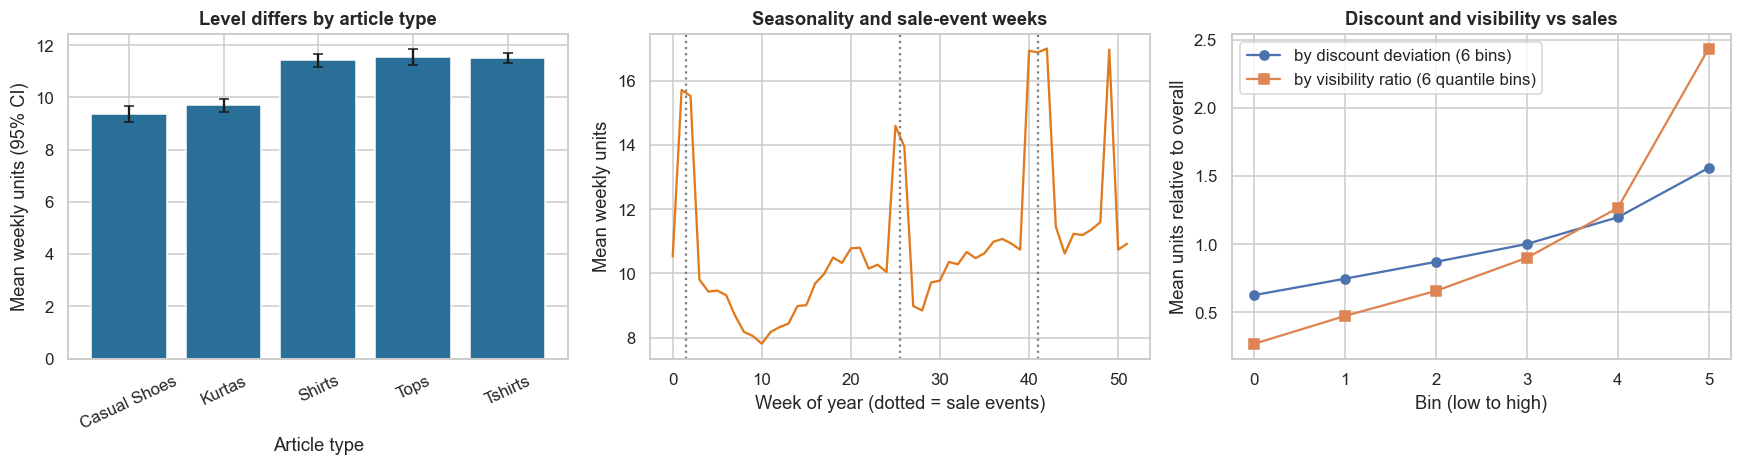

{'Casual Shoes': 9.4, 'Kurtas': 9.7, 'Shirts': 11.4, 'Tops': 11.5, 'Tshirts': 11.5}
Sale-event weeks vs other weeks: 16.0 vs 10.0; top visibility bin / bottom bin = 9.1x; top discount bin / bottom bin = 2.5x


In [7]:
dm = d1.merge(styles[["style_id", "article_type", "colour", "price_band"]], on="style_id")
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
bt = dm.groupby("article_type").units_sold.agg(["mean", "std", "size"]); bt["se"] = bt["std"] / np.sqrt(bt["size"]); axes[0].bar(bt.index, bt["mean"], yerr=1.96 * bt["se"], color="#2a6f97", capsize=3); axes[0].set_xlabel("Article type"); axes[0].set_ylabel("Mean weekly units (95% CI)"); axes[0].set_title("Level differs by article type"); axes[0].tick_params(axis="x", rotation=25)
wk_m = dm.groupby(dm.week % 52).units_sold.mean(); axes[1].plot(wk_m.index, wk_m.values, color="#e07a1f"); [axes[1].axvline(x, color="grey", ls=":") for x in (1.5, 25.5, 41)]; axes[1].set_xlabel("Week of year (dotted = sale events)"); axes[1].set_ylabel("Mean weekly units"); axes[1].set_title("Seasonality and sale-event weeks")
dm["disc_bin"] = pd.cut(dm.discount_dev_pp, [-100, -10, -5, 0, 5, 10, 100]); dm["vis_bin"] = pd.qcut(dm.visibility_ratio, 6, duplicates="drop")
a1 = dm.groupby("disc_bin").units_sold.mean(); a2 = dm.groupby("vis_bin").units_sold.mean(); axes[2].plot(range(len(a1)), a1.values / a1.mean(), marker="o", label="by discount deviation (6 bins)"); axes[2].plot(range(len(a2)), a2.values / a2.mean(), marker="s", label="by visibility ratio (6 quantile bins)"); axes[2].set_xlabel("Bin (low to high)"); axes[2].set_ylabel("Mean units relative to overall"); axes[2].set_title("Discount and visibility vs sales"); axes[2].legend()
plt.tight_layout(); plt.show()
print(bt["mean"].round(1).to_dict()); print(f"Sale-event weeks vs other weeks: {dm[dm.week.isin(gen.promo_calendar())].units_sold.mean():.1f} vs {dm[~dm.week.isin(gen.promo_calendar())].units_sold.mean():.1f}; top visibility bin / bottom bin = {a2.iloc[-1] / a2.iloc[0]:.1f}x; top discount bin / bottom bin = {a1.iloc[-1] / a1.iloc[0]:.1f}x")

**Takeaway:** Article types are close in mean weekly units (9.4 for casual shoes to 11.5 for tops and T-shirts). Sale-event weeks sell 16.0 units against 10.0 otherwise. The top visibility bin sells 9.1 times the bottom bin and the top discount bin 2.5 times, but visibility is partly an effect of demand (checked in 7.6), so the 9.1 times is not a causal effect.

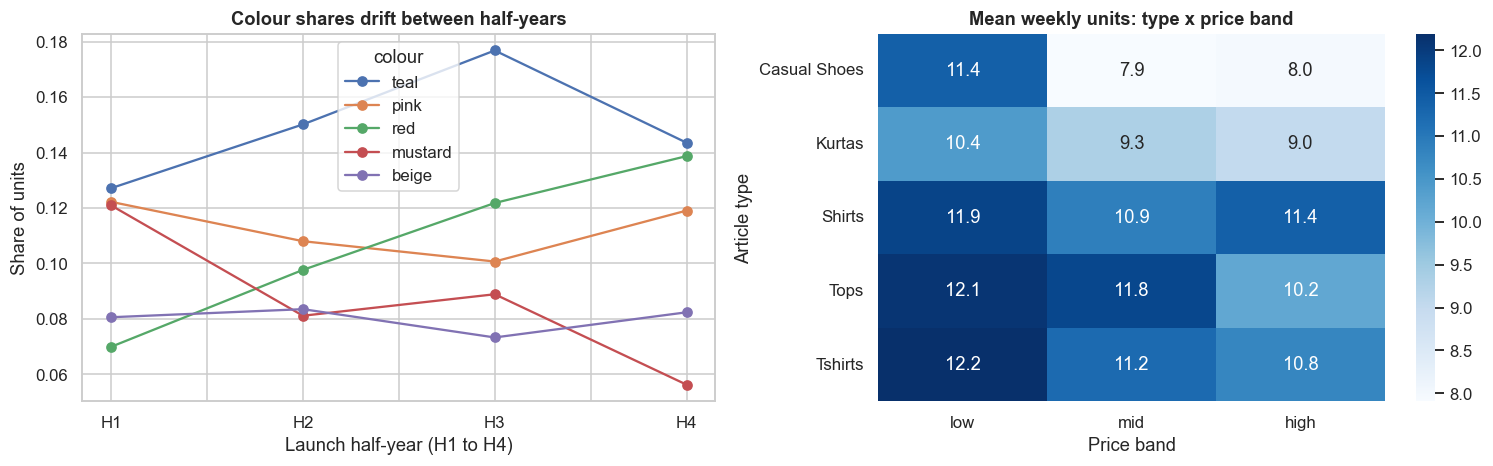

{'teal': 0.05, 'pink': 0.022, 'red': 0.069, 'mustard': 0.065, 'beige': 0.01} (max-min share across half-years, top-5 colours)


In [8]:
dm["half"] = "H" + (dm.launch_week // 26 + 1).astype(str)
top = dm.groupby("colour").units_sold.sum().sort_values(ascending=False).head(5).index
sh = dm.groupby(["half", "colour"]).units_sold.sum().unstack().fillna(0); sh = sh.div(sh.sum(1), axis=0)[top]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
sh.plot(ax=axes[0], marker="o"); axes[0].set_xlabel("Launch half-year (H1 to H4)"); axes[0].set_ylabel("Share of units"); axes[0].set_title("Colour shares drift between half-years")
ct = dm.groupby(["article_type", "price_band"]).units_sold.mean().unstack()[["low", "mid", "high"]]; sns.heatmap(ct, annot=True, fmt=".1f", cmap="Blues", ax=axes[1]); axes[1].set_xlabel("Price band"); axes[1].set_ylabel("Article type"); axes[1].set_title("Mean weekly units: type x price band")
plt.tight_layout(); plt.show()
print((sh.max() - sh.min()).round(3).to_dict(), "(max-min share across half-years, top-5 colours)")

**Takeaway:** Colour shares move by up to 6.9 percentage points between half-years (red), so colour popularity drifts. This is why a launch-date split is the fair test: the future launches have a different colour mix.

## 7. Statistical Analysis (core section)

### 7.1 Setup: features, launch-date split and 8 models against the naive baseline

**Features** follow the documented families: attributes (type, brand tier, brand, price band, colour, material, pattern, log price); merchandising (discount deviation, visibility ratio) and promotion calendar (sale-week flag, weeks to next and since last sale); time (style age and three Fourier seasonality pairs of the week of year); cannibalisation (styles listed that week in the same article type and price band, and by the same brand). Merchandising, promotion and listing counts are taken from the **plan** (known before the week). No own-sales lags are used in the cold-start models (see 7.7 for early sales).

**Split by launch date** (documented): train = launches in weeks 0 to 51, validation = 52 to 77, test = 78 to 103. The **champion** is chosen on validation wMAPE only, then reported on the test set.

#### Code

In [9]:
promo = np.sort(gen.promo_calendar())
df = d1.merge(styles.drop(columns=["_quality"]), on="style_id", suffixes=("", "_s")); df = df.drop(columns=[c for c in df.columns if c.endswith("_s")]).sort_values(["style_id", "week"]).reset_index(drop=True)
df["n_tb"] = df.groupby(["article_type", "price_band", "week"]).style_id.transform("size"); df["n_brand"] = df.groupby(["brand_id", "week"]).style_id.transform("size")
df["is_promo"] = df.week.isin(promo).astype(int)
nxt = np.searchsorted(promo, df.week.values); df["wk_to_promo"] = np.where(nxt < len(promo), promo[np.minimum(nxt, len(promo) - 1)] - df.week.values, 26).clip(0, 26)
prv = np.searchsorted(promo, df.week.values, side="right") - 1; df["wk_from_promo"] = np.where(prv >= 0, df.week.values - promo[np.maximum(prv, 0)], 26).clip(0, 26)
woy = 2 * np.pi * (df.week % 52) / 52
for h in (1, 2, 3): df[f"s{h}"] = np.sin(h * woy); df[f"c{h}"] = np.cos(h * woy)
df["log_price"] = np.log(df.list_price_inr); df["log_vis"] = np.log(np.maximum(df.visibility_ratio, 0.05)); df["log_ntb"] = np.log(df.n_tb / 25.0); df["log_nbr"] = np.log(np.maximum(df.n_brand, 1)); df["age_decay"] = np.exp(-df.age / 2.5)
CATS = ["article_type", "brand_tier", "price_band", "colour", "material", "pattern", "brand_id"]; FOUR = ["s1", "c1", "s2", "c2", "s3", "c3"]
NUM = ["log_price", "discount_dev_pp", "visibility_ratio", "age", "n_tb", "n_brand", "is_promo", "wk_to_promo", "wk_from_promo"] + FOUR
Xc = df[CATS + NUM].copy()
for c in CATS: Xc[c] = Xc[c].astype("category")
Xo = pd.get_dummies(df[CATS + NUM], columns=CATS, dtype=float); y = df.units_sold.values.astype(float)
tr = (df.launch_week < 52).values; va = ((df.launch_week >= 52) & (df.launch_week < 78)).values; te = (df.launch_week >= 78).values
print(f"Rows: train {tr.sum():,} ({df[tr].style_id.nunique():,} styles) | validation {va.sum():,} ({df[va].style_id.nunique():,}) | test {te.sum():,} ({df[te].style_id.nunique():,}) | features {len(CATS) + len(NUM)} ({Xo.shape[1]} after one-hot)")
HG = dict(max_iter=300, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=40, l2_regularization=1.0, random_state=SEED)
SPEC = {"GBRT MSE (raw units)": ("squared_error", False), "GBRT Poisson": ("poisson", False), "GBRT MSE (log scale)": ("squared_error", True)}
def fit_hgb(spec, X, yy, **kw):
    loss, lg = SPEC[spec] if isinstance(spec, str) else spec
    m = HistGradientBoostingRegressor(loss=loss, categorical_features="from_dtype", **{**HG, **kw}).fit(X, np.log1p(yy) if lg else yy); return m
def pred_hgb(m, X, spec):
    lg = (SPEC[spec] if isinstance(spec, str) else spec)[1]; p = m.predict(X); return np.maximum(np.expm1(p) if lg else p, 0.0)
PRED, OBJ, FITSEC = {}, {}, {}
t0 = time.time()
PRED["naive: average style-week"] = np.full(len(df), y[tr].mean())
tm = pd.Series(y[tr]).groupby(df.article_type.values[tr]).mean(); PRED["article-type average"] = df.article_type.map(tm).values
sc = StandardScaler().fit(Xo[tr]); Zs = sc.transform(Xo)
pr = PoissonRegressor(alpha=1e-3, max_iter=500).fit(Zs[tr], y[tr]); PRED["Poisson linear (one-hot)"] = pr.predict(Zs); FITSEC["Poisson linear (one-hot)"] = time.time() - t0
t1 = time.time(); rf = RandomForestRegressor(n_estimators=120, min_samples_leaf=25, max_features=0.4, n_jobs=2, random_state=SEED).fit(Xo[tr], y[tr]); PRED["Random forest (MSE)"] = rf.predict(Xo); FITSEC["Random forest (MSE)"] = time.time() - t1
for k in SPEC:
    t1 = time.time(); OBJ[k] = fit_hgb(k, Xc[tr], y[tr]); PRED[k] = pred_hgb(OBJ[k], Xc, k); FITSEC[k] = time.time() - t1
t1 = time.time(); mlp = MLPRegressor(hidden_layer_sizes=(64, 32), alpha=1e-3, max_iter=60, early_stopping=True, random_state=SEED).fit(Zs[tr], np.log1p(y[tr])); PRED["MLP (log scale)"] = np.maximum(np.expm1(mlp.predict(Zs)), 0); FITSEC["MLP (log scale)"] = time.time() - t1
def wmape(a, p): return np.abs(a - p).sum() / a.sum()
tcode = pd.factorize(df.style_id.values[te])[0]; nT = tcode.max() + 1; BIDX = RNG.integers(0, nT, (1000, nT)); ys_t = np.bincount(tcode, y[te], nT)
def boot(p):
    ea = np.bincount(tcode, np.abs(y[te] - p[te]), nT); return ea[BIDX].sum(1) / ys_t[BIDX].sum(1)
BT = {k: boot(p) for k, p in PRED.items()}
rows = []
for k, p in PRED.items(): rows.append((k, wmape(y[va], p[va]), wmape(y[te], p[te]), np.percentile(BT[k], 2.5), np.percentile(BT[k], 97.5), p[te].sum() / y[te].sum() - 1, np.corrcoef(y[te], p[te])[0, 1]))
res = pd.DataFrame(rows, columns=["model", "val wMAPE", "test wMAPE", "CI low", "CI high", "bias (sum fcst / sum actual - 1)", "Pearson r (style-week)"]).set_index("model")
CAND = [k for k in res.index if not k.startswith("naive") and not k.startswith("article")]; CH = res.loc[CAND, "val wMAPE"].idxmin()
WORK = res.loc[list(SPEC), "val wMAPE"].idxmin()
print(f"Champion on validation (any model): {CH} | best boosted model on validation (used from 7.4 on): {WORK} | fit times (s): " + ", ".join(f"{k.split(' (')[0]} {v:.0f}" for k, v in FITSEC.items()))
res.round(4)

Rows: train 50,919 (4,460 styles) | validation 25,555 (2,244) | test 26,543 (2,296) | features 22 (89 after one-hot)


Champion on validation (any model): GBRT MSE (log scale) | best boosted model on validation (used from 7.4 on): GBRT MSE (log scale) | fit times (s): Poisson linear 63, Random forest 43, GBRT MSE 1038, GBRT Poisson 297, GBRT MSE 49, MLP 26


,val wMAPE,test wMAPE,CI low,CI high,bias (sum fcst / sum actual - 1),Pearson r (style-week)
model,,,,,,
naive: average style-week,0.9416,0.8700,0.8509,0.8902,-0.1282,NaN
article-type average,0.9431,0.8654,0.8467,0.8863,-0.1289,0.0728
Poisson linear (one-hot),0.6281,0.6370,0.6220,0.6535,-0.0695,0.4888
Random forest (MSE),0.6781,0.6637,0.6506,0.6769,-0.0760,0.5625
GBRT MSE (raw units),0.6241,0.6255,0.6135,0.6374,-0.0719,0.6415
GBRT Poisson,0.6127,0.6091,0.5980,0.6202,-0.1369,0.6435
GBRT MSE (log scale),0.5894,0.5965,0.5859,0.6072,-0.3216,0.6491
MLP (log scale),0.6771,0.6654,0.6522,0.6781,-0.2775,0.5484


**(c)/(f) Observation:** The best model on validation is gradient boosting on log units (validation wMAPE 0.589, test 0.597, CI 0.586 to 0.607). The two baselines are far behind (test 0.870 and 0.865, so the article type alone adds almost nothing). Poisson boosting (0.609) and raw-MSE boosting (0.626) are next, then Poisson linear (0.637), random forest (0.664) and the MLP (0.665). The log model has the highest correlation (0.649) but the largest low bias (-32.2%); wMAPE rewards a median-like forecast, so its total is too low (see 7.4). The raw-MSE boosted model took far longer to fit than the others on this shared machine (1,038 s against 49 s for the log model), which is a nuisance, not a finding.

#### By article type (the paper's table: naive vs best model)

In [10]:
rows = []
for a in sorted(df.article_type.unique()):
    m_ = te & (df.article_type == a).values; sc_ = pd.factorize(df.style_id.values[m_])[0]; n_ = sc_.max() + 1; ix = RNG.integers(0, n_, (500, n_)); ys = np.bincount(sc_, y[m_], n_)
    def bw(p): ea = np.bincount(sc_, np.abs(y[m_] - p[m_]), n_); return ea[ix].sum(1) / ys[ix].sum(1)
    bn, bc = bw(PRED["naive: average style-week"]), bw(PRED[CH]); rows.append((a, n_, wmape(y[m_], PRED["naive: average style-week"][m_]), wmape(y[m_], PRED[CH][m_]), np.percentile(bc, 2.5), np.percentile(bc, 97.5), (bn - bc).mean()))
bytype = pd.DataFrame(rows, columns=["article type", "test styles", "naive wMAPE", f"{CH} wMAPE", "CI low", "CI high", "improvement (naive - model)"]).set_index("article type")
bytype.round(3)

,test styles,naive wMAPE,GBRT MSE (log scale) wMAPE,CI low,CI high,improvement (naive - model)
article type,,,,,,
Casual Shoes,288,1.0280,0.5920,0.5690,0.6130,0.4410
Kurtas,408,1.0050,0.6130,0.5950,0.6310,0.3950
Shirts,513,0.8490,0.5900,0.5710,0.6120,0.2590
Tops,471,0.8370,0.6170,0.5920,0.6440,0.2190
Tshirts,616,0.8020,0.5760,0.5620,0.5920,0.2260


**Observation (by type):** Every article type improves a lot, from 0.22 (Tops) to 0.44 (Casual Shoes) in wMAPE, with model wMAPE between 0.576 and 0.617. The paper reports naive values near 1.0 and best values of 0.51 to 0.60; our naive values are 0.80 to 1.03 and our best 0.58 to 0.62, so the size of the gain is of the same order, but this is a simulation tuned by us and not a confirmation of their numbers.

### 7.2 Is the champion really better? Paired bootstrap on test styles, Holm-adjusted

**(a) Why?** Every model forecasts the same test style-weeks, so differences must be paired, and style-weeks of one style are correlated, so we **resample whole styles** (1,000 resamples, same resamples for all models). Hypotheses: H1 (champion vs naive) and H2 (champion vs each other model): H0: wMAPE difference = 0. Two-sided bootstrap p-value = 2 × min(share of resamples ≤ 0, share ≥ 0), floored at 1/1,000; Holm correction across all comparisons.

#### Code

In [11]:
rows = []
for k in res.index:
    if k == CH: continue
    d = BT[k] - BT[CH]; p_ = max(2 * min((d <= 0).mean(), (d >= 0).mean()), 1 / 1000); rows.append((k, wmape(y[te], PRED[k][te]) - wmape(y[te], PRED[CH][te]), np.percentile(d, 2.5), np.percentile(d, 97.5), p_))
pt = pd.DataFrame(rows, columns=[f"vs {CH}", "wMAPE difference (other - champion)", "CI low", "CI high", "bootstrap p"]).set_index(f"vs {CH}"); pt["p_holm"] = multipletests(pt["bootstrap p"], method="holm")[1]
print(f"Champion: {CH}; test wMAPE {res.loc[CH, 'test wMAPE']:.4f} (CI {res.loc[CH, 'CI low']:.4f} to {res.loc[CH, 'CI high']:.4f}); naive {res.loc['naive: average style-week', 'test wMAPE']:.4f}")
pt.round(4)

Champion: GBRT MSE (log scale); test wMAPE 0.5965 (CI 0.5859 to 0.6072); naive 0.8700


,wMAPE difference (other - champion),CI low,CI high,bootstrap p,p_holm
vs GBRT MSE (log scale),,,,,
naive: average style-week,0.2736,0.2556,0.2924,0.0010,0.0070
article-type average,0.2689,0.2517,0.2871,0.0010,0.0070
Poisson linear (one-hot),0.0405,0.0268,0.0550,0.0010,0.0070
Random forest (MSE),0.0673,0.0568,0.0780,0.0010,0.0070
GBRT MSE (raw units),0.0290,0.0194,0.0389,0.0010,0.0070
GBRT Poisson,0.0126,0.0055,0.0202,0.0010,0.0070
MLP (log scale),0.0689,0.0591,0.0792,0.0010,0.0070


**(c)/(f) Observation:** H1 is rejected: the champion beats the naive average by 0.274 wMAPE (CI 0.256 to 0.292). H2 is rejected for every other model after Holm correction (adjusted p = 0.007 each, the floor with 1,000 resamples). The closest rival is Poisson boosting (difference 0.013, CI 0.006 to 0.020), so the choice of loss is a small effect next to the effect of using attributes at all. The random forest and the MLP are clearly worse (0.067 and 0.069).

### 7.3 Random split vs out-of-time split: how optimistic is a random split?

**(a) Why?** The paper validates by launch date. A random split lets the model see other weeks of the same style, or styles from the same calendar period as the test, so it can look better than it will on genuinely future launches. We refit the working model (the best boosted model on validation) with the same settings on (i) a **random split of style-weeks** (leaky: the same style appears on both sides), (ii) a **random split of styles**, and compare with the out-of-time test. Test sets differ, so we report each wMAPE with its own bootstrap CI and the difference with an independent-bootstrap CI.

#### Code

In [12]:
spw = SPEC[WORK]; rs = np.random.default_rng(SEED); out = {}
perm = rs.permutation(len(df)); a_tr, a_te = np.zeros(len(df), bool), np.zeros(len(df), bool); a_tr[perm[: int(0.5 * len(df))]] = True; a_te[perm[int(0.5 * len(df)): int(0.75 * len(df))]] = True
us = rs.permutation(df.style_id.unique()); b_tr_ids, b_te_ids = us[: len(us) // 2], us[len(us) // 2: int(0.75 * len(us))]; b_tr = df.style_id.isin(b_tr_ids).values; b_te = df.style_id.isin(b_te_ids).values
def cl_boot(mask, p, by_style=True, B=500):
    codes = pd.factorize(df.style_id.values[mask])[0] if by_style else np.arange(mask.sum()); n_ = codes.max() + 1; ix = rs.integers(0, n_, (B, n_)); ea = np.bincount(codes, np.abs(y[mask] - p[mask]), n_); ys = np.bincount(codes, y[mask], n_); return ea[ix].sum(1) / ys[ix].sum(1)
for name, trm, tem, bys in [("random split of style-weeks (leaky)", a_tr, a_te, False), ("random split of styles", b_tr, b_te, True)]:
    m_ = fit_hgb(WORK, Xc[trm], y[trm]); p_ = pred_hgb(m_, Xc, WORK); bs = cl_boot(tem, p_, bys); out[name] = (wmape(y[tem], p_[tem]), np.percentile(bs, 2.5), np.percentile(bs, 97.5), bs)
bo = BT[WORK]; out["out-of-time (launch-date) test"] = (wmape(y[te], PRED[WORK][te]), np.percentile(bo, 2.5), np.percentile(bo, 97.5), bo)
sp = pd.DataFrame({k: v[:3] for k, v in out.items()}, index=["wMAPE", "CI low", "CI high"]).T
for k in list(out)[:2]:
    d = out["out-of-time (launch-date) test"][3][:500] - out[k][3]; sp.loc[k, "optimism vs out-of-time (time - random)"] = out["out-of-time (launch-date) test"][0] - out[k][0]; sp.loc[k, "diff CI low"] = np.percentile(d, 2.5); sp.loc[k, "diff CI high"] = np.percentile(d, 97.5)
print(f"Working model: {WORK}")
sp.round(4)

Working model: GBRT MSE (log scale)


,wMAPE,CI low,CI high,optimism vs out-of-time (time - random),diff CI low,diff CI high
random split of style-weeks (leaky),0.5474,0.5402,0.5537,0.0491,0.0364,0.0622
random split of styles,0.5698,0.5608,0.5789,0.0267,0.0121,0.0406
out-of-time (launch-date) test,0.5965,0.5859,0.6072,NaN,NaN,NaN


**Observation:** H3 is rejected. A random split of style-weeks gives wMAPE 0.547 and is 0.049 too optimistic (CI 0.036 to 0.062) because the same style sits on both sides. A random split of styles is 0.570, 0.027 too optimistic (CI 0.012 to 0.041), because the test styles share a calendar with the training styles. Only the launch-date test (0.597) is honest, and even it ignores a real trend break.

### 7.4 Is the forecast calibrated, and how wide is the uncertainty?

**(a) Why?** A buyer needs the total to be right and needs to know how wrong a style-week can be. (1) **Calibration slope:** Poisson regression of actual units on log(forecast) with style-clustered standard errors; H0: slope = 1 (a slope below 1 means forecasts are too spread out, above 1 too compressed). (2) **Bias** by forecast decile. (3) **80% prediction interval** from 10% and 90% quantile gradient boosting, then **split-conformal adjustment** using the validation period (adds the 80% quantile of validation non-conformity scores). H0: coverage = 80%; CI from the style bootstrap.

#### Code

In [13]:
pw = np.maximum(PRED[WORK], 0.05); cal = sm.GLM(y[te], sm.add_constant(np.log(pw[te])), family=sm.families.Poisson()).fit(cov_type="cluster", cov_kwds={"groups": df.style_id.values[te]})
sl_, se_ = cal.params[1], cal.bse[1]; print(f"Calibration slope (Poisson, cluster-robust): {sl_:.3f} (95% CI {sl_ - 1.96 * se_:.3f} to {sl_ + 1.96 * se_:.3f}); test of slope = 1: p = {2 * stats.norm.sf(abs(sl_ - 1) / se_):.3g}; intercept {cal.params[0]:.3f}")
dec = pd.qcut(PRED[WORK][te], 10, labels=False, duplicates="drop"); cd = pd.DataFrame({"forecast": PRED[WORK][te], "actual": y[te], "d": dec}).groupby("d").agg(mean_forecast=("forecast", "mean"), mean_actual=("actual", "mean"), n=("actual", "size")); cd["actual / forecast"] = cd.mean_actual / cd.mean_forecast
q = {}
for a_ in (0.1, 0.9):
    mm = HistGradientBoostingRegressor(loss="quantile", quantile=a_, categorical_features="from_dtype", **HG).fit(Xc[tr], y[tr]); q[a_] = np.maximum(mm.predict(Xc), 0)
lo, hi = q[0.1], np.maximum(q[0.9], q[0.1])
s_va = np.maximum(lo[va] - y[va], y[va] - hi[va]); nv = va.sum(); qh = np.quantile(s_va, min(1.0, np.ceil((nv + 1) * 0.8) / nv)); lo_c, hi_c = np.maximum(lo - qh, 0), hi + qh
def cov_ci(l, h):
    c = ((y >= l) & (y <= h)).astype(float)[te]; cs_ = np.bincount(tcode, c, nT); n_s = np.bincount(tcode, minlength=nT); b = cs_[BIDX].sum(1) / n_s[BIDX].sum(1); return c.mean(), np.percentile(b, 2.5), np.percentile(b, 97.5)
cv = pd.DataFrame({"raw quantile interval (10% to 90%)": cov_ci(lo, hi), f"conformal-adjusted (+{qh:.1f} units)": cov_ci(lo_c, hi_c)}, index=["coverage", "CI low", "CI high"]).T; cv["mean width (units)"] = [(hi - lo)[te].mean(), (hi_c - lo_c)[te].mean()]
print(f"Overall bias (sum forecast / sum actual - 1): {PRED[WORK][te].sum() / y[te].sum() - 1:+.1%}")
display(cd.round(3)); cv.round(4)

Calibration slope (Poisson, cluster-robust): 1.027 (95% CI 0.985 to 1.070); test of slope = 1: p = 0.207; intercept 0.319


Overall bias (sum forecast / sum actual - 1): -32.2%


,mean_forecast,mean_actual,n,actual / forecast
d,,,,
0,1.0910,1.7590,2655,1.6130
1,2.0410,3.1760,2654,1.5570
2,2.8600,4.3930,2654,1.5360
3,3.7750,5.3980,2654,1.4300
4,4.8210,7.0450,2655,1.4610
5,6.1510,9.0150,2654,1.4660
6,7.9150,11.1900,2654,1.4140
7,10.4270,14.8290,2654,1.4220
8,14.8490,20.9710,2654,1.4120


,coverage,CI low,CI high,mean width (units)
raw quantile interval (10% to 90%),0.7154,0.7068,0.7239,17.6675
conformal-adjusted (+0.4 units),0.7769,0.7689,0.7854,18.3236


**Observation:** H4 is partly rejected. The calibration slope is 1.027 (CI 0.985 to 1.070, p = 0.21), so the forecasts are not too spread out or too compressed. But the intercept is 0.319 and the total is 32.2% low: in every forecast decile actual units are 1.41 to 1.61 times the forecast. This is the known cost of a log-scale loss. The nominal 80% interval covered 71.5% (CI 70.7% to 72.4%); the conformal adjustment of 0.4 units lifted coverage to 77.7% (CI 76.9% to 78.5%) but still fell short of 80%, because the validation period differs from the test period. Use the model for shares, and rescale the volume with a calibration factor or the Poisson model.

### 7.5 Does the forecast rank attribute combinations for buying budgets?

**(a) Why?** The paper aggregates forecasts to **attribute combinations** to guide budgets. Here a combination is article type × colour × price band (≥ 3 test styles). We compare forecast and actual total units per combination with **Pearson** and **Kendall Tau** (the paper's metrics), plus **top-quintile capture**: the share of actual units that fall in the 20% of combinations the forecast ranks highest (random would capture 20%). 95% CIs by resampling test styles (500). H0: Tau = 0.

#### Code

In [14]:
tdf = df[te].copy(); tdf["p_work"] = PRED[WORK][te]; tdf["p_naive"] = PRED["naive: average style-week"][te]; tdf["p_type"] = PRED["article-type average"][te]; tdf["p_lin"] = PRED["Poisson linear (one-hot)"][te]
sty = tdf.groupby("style_id").agg(y=("units_sold", "sum"), naive=("p_naive", "sum"), typ=("p_type", "sum"), lin=("p_lin", "sum"), work=("p_work", "sum"), oracle=("_mu", "sum"), article_type=("article_type", "first"), colour=("colour", "first"), price_band=("price_band", "first"))
sty["combo"] = sty.article_type + "|" + sty.colour + "|" + sty.price_band; sty["cc"] = pd.factorize(sty.combo)[0]; ncombo = sty.cc.max() + 1; ok_c = np.bincount(sty.cc) >= 3
print(f"{ncombo} combinations, {ok_c.sum()} with >= 3 test styles (median {np.median(np.bincount(sty.cc)[ok_c]):.0f} styles)")
MODS = {"naive (no forecast: styles listed)": "naive", "article-type average": "typ", "Poisson linear": "lin", f"working model ({WORK})": "work", "oracle (true expected demand)": "oracle"}
ar = {c: sty[c].values for c in ["y", "naive", "typ", "lin", "work", "oracle"]}; cc_all = sty.cc.values
def combo_stats(cnt):
    A = np.bincount(cc_all, ar["y"] * cnt, ncombo)[ok_c]; k_ = int(np.ceil(0.2 * len(A))); r_ = {}
    for lab, col in MODS.items():
        P = np.bincount(cc_all, ar[col] * cnt, ncombo)[ok_c]; r_[lab] = (np.corrcoef(A, P)[0, 1], stats.kendalltau(A, P)[0], A[np.argsort(-P)[:k_]].sum() / A.sum())
    return r_
base = combo_stats(np.ones(len(sty))); bsr = [combo_stats(np.bincount(RNG.integers(0, len(sty), len(sty)), minlength=len(sty))) for _ in range(500)]
rows = []
for lab in MODS:
    arr = np.array([b[lab] for b in bsr]); A0 = np.bincount(sty.cc.values, sty.y.values, ncombo)[ok_c]; P0 = np.bincount(sty.cc.values, sty[MODS[lab]].values, ncombo)[ok_c]
    rows.append((lab, base[lab][0], np.percentile(arr[:, 0], 2.5), np.percentile(arr[:, 0], 97.5), base[lab][1], np.percentile(arr[:, 1], 2.5), np.percentile(arr[:, 1], 97.5), stats.kendalltau(A0, P0)[1], base[lab][2], np.percentile(arr[:, 2], 2.5), np.percentile(arr[:, 2], 97.5)))
cb = pd.DataFrame(rows, columns=["forecast", "Pearson r", "r low", "r high", "Kendall Tau", "tau low", "tau high", "tau p-value", "top-20% capture", "cap low", "cap high"]).set_index("forecast")
A0 = np.bincount(sty.cc.values, sty.y.values, ncombo)[ok_c]; best_cap = np.sort(A0)[::-1][: int(np.ceil(0.2 * len(A0)))].sum() / A0.sum(); print(f"Best possible top-20% capture (ranking by actual): {best_cap:.3f}")
cb.round(4)

180 combinations, 180 with >= 3 test styles (median 13 styles)


Best possible top-20% capture (ranking by actual): 0.449


,Pearson r,r low,r high,Kendall Tau,tau low,tau high,tau p-value,top-20% capture,cap low,cap high
forecast,,,,,,,,,,
naive (no forecast: styles listed),0.6343,0.5526,0.7025,0.5270,0.4900,0.5917,0.0000,0.3625,0.3323,0.4256
article-type average,0.6508,0.5670,0.7172,0.5450,0.5047,0.6027,0.0000,0.3634,0.3451,0.4332
Poisson linear,0.8434,0.8061,0.8830,0.6973,0.6850,0.7456,0.0000,0.4232,0.4153,0.4845
working model (GBRT MSE (log scale)),0.8763,0.8293,0.9058,0.7087,0.7017,0.7606,0.0000,0.4204,0.4149,0.4822
oracle (true expected demand),0.9957,0.9896,0.9961,0.9457,0.9333,0.9509,0.0000,0.4477,0.4578,0.5140


**Observation:** H5 is rejected (Kendall Tau p-values are below 1e-4 for every forecast). Across 180 combinations the champion gives Pearson r = 0.876 (CI 0.829 to 0.906) and Tau = 0.709 (CI 0.702 to 0.761), against the naive 0.634 and 0.527. The Poisson linear model is nearly as good (r = 0.843, Tau = 0.697), so for combination-level buying a simple model is competitive. The top-20% capture is 42.0% for the champion and 42.3% for the Poisson linear model, against 36.3% for the naive forecast and a best possible 44.9%. The oracle's point value (0.448) sits below its own bootstrap interval (0.458 to 0.514): the percentile bootstrap on a ranking statistic is biased, so read these capture intervals loosely.

### 7.6 What drives demand? A driver analysis checked against the hidden truth

**(a) Why?** Buyers want to know *why*, for example how much a discount or a better list-page position adds. We fit a **Poisson regression** (log link) on the training cohort with style-clustered standard errors and read the coefficients **by name**. Visibility is partly **caused by style quality** (the platform shows what sells), so a naive model should overstate the visibility effect. Because the simulation exposes the hidden quality, we can show the biased estimate, the estimate after controlling for quality (not possible in real data), and the true value built into the generator. We also report **grouped permutation importance** of the working model on the test set (increase in wMAPE when a feature group is shuffled, 5 repeats). H0 (H6): the naive visibility coefficient equals the true 0.50.

#### Code

In [15]:
trd = df[tr].merge(styles[["style_id", "_quality"]].rename(columns={"_quality": "qual"}), on="style_id")
base_f = "units_sold ~ discount_dev_pp + log_vis + is_promo + log_ntb + log_nbr + age + age_decay + s1 + c1 + s2 + c2 + s3 + c3 + C(article_type) + C(brand_tier) + C(price_band) + C(colour) + C(material) + C(pattern)"
g1 = smf.glm(base_f, data=trd, family=sm.families.Poisson()).fit(cov_type="cluster", cov_kwds={"groups": trd.style_id.values}); g2 = smf.glm(base_f + " + qual", data=trd, family=sm.families.Poisson()).fit(cov_type="cluster", cov_kwds={"groups": trd.style_id.values})
TRUE = {"discount_dev_pp": 0.022, "log_vis": 0.50, "is_promo": 0.22, "log_ntb": -0.14, "log_nbr": -0.06}
rows = []
for n_, t_ in TRUE.items(): rows.append((n_, t_, g1.params[n_], g1.conf_int().loc[n_, 0], g1.conf_int().loc[n_, 1], g2.params[n_], g2.conf_int().loc[n_, 0], g2.conf_int().loc[n_, 1]))
drv = pd.DataFrame(rows, columns=["coefficient", "true (generator)", "naive estimate", "naive low", "naive high", "quality-adjusted", "adj low", "adj high"]).set_index("coefficient")
print(f"Visibility z-test, naive estimate vs 0.50: z = {(g1.params['log_vis'] - 0.5) / g1.bse['log_vis']:.1f}; quality-adjusted vs 0.50: z = {(g2.params['log_vis'] - 0.5) / g2.bse['log_vis']:.1f} | +10pp discount multiplies units by {np.exp(10 * g1.params['discount_dev_pp']):.2f} (true {np.exp(0.22):.2f})")
drv.round(3)

Visibility z-test, naive estimate vs 0.50: z = 38.6; quality-adjusted vs 0.50: z = -2.6 | +10pp discount multiplies units by 1.25 (true 1.25)


,true (generator),naive estimate,naive low,naive high,quality-adjusted,adj low,adj high
coefficient,,,,,,,
discount_dev_pp,0.0220,0.0230,0.0210,0.0240,0.0230,0.0210,0.0240
log_vis,0.5000,1.6480,1.5900,1.7070,0.4550,0.4200,0.4890
is_promo,0.2200,0.1900,0.1540,0.2260,0.1940,0.1640,0.2240
log_ntb,-0.1400,-0.0790,-0.1660,0.0070,-0.1030,-0.1730,-0.0340
log_nbr,-0.0600,-0.0520,-0.1470,0.0440,-0.0120,-0.0800,0.0570


In [16]:
GROUPS = {"attributes (type, brand, colour, ...)": CATS + ["log_price"], "merchandising (discount, visibility)": ["discount_dev_pp", "visibility_ratio"], "style age": ["age"], "seasonality (Fourier)": FOUR, "promotion calendar": ["is_promo", "wk_to_promo", "wk_from_promo"], "cannibalisation (listing counts)": ["n_tb", "n_brand"]}
Xte = Xc[te].reset_index(drop=True); yte = y[te]; base_w = wmape(yte, pred_hgb(OBJ[WORK], Xte, WORK)); rows = []; rp = np.random.default_rng(SEED)
for gname, cols in GROUPS.items():
    inc = []
    for r in range(5):
        pm = rp.permutation(len(Xte)); Xp = Xte.copy()
        for c in cols: Xp[c] = Xte[c].iloc[pm].set_axis(Xte.index)
        inc.append(wmape(yte, pred_hgb(OBJ[WORK], Xp, WORK)) - base_w)
    rows.append((gname, np.mean(inc), np.std(inc, ddof=1)))
imp = pd.DataFrame(rows, columns=["feature group", "wMAPE increase when shuffled", "sd over 5 repeats"]).set_index("feature group").sort_values("wMAPE increase when shuffled", ascending=False)
print(f"Baseline test wMAPE of {WORK}: {base_w:.4f}")
imp.round(4)

Baseline test wMAPE of GBRT MSE (log scale): 0.5965


,wMAPE increase when shuffled,sd over 5 repeats
feature group,,
"merchandising (discount, visibility)",0.2060,0.0032
"attributes (type, brand, colour, ...)",0.1273,0.0022
style age,0.0423,0.0008
seasonality (Fourier),0.0102,0.0005
promotion calendar,0.0083,0.0009
cannibalisation (listing counts),0.0043,0.0005


**Observation:** H6 is rejected. The naive visibility coefficient is 1.648 (CI 1.590 to 1.707) against a true 0.50, more than three times too large, because visibility partly reflects hidden style quality. With the quality term it is 0.455 (CI 0.420 to 0.489), still slightly below 0.50 (z = -2.6). The discount effect is recovered either way (0.023 vs 0.022; +10 points of discount multiplies units by 1.25, the true value). The promotion effect is 0.19 (true 0.22), and cannibalisation effects are small and noisy. By shuffling feature groups, merchandising matters most (wMAPE +0.206), then attributes (+0.127), age (+0.042), seasonality (+0.010), promotion calendar (+0.008) and cannibalisation (+0.004). Because merchandising is so strong, a forecast made before the plan is fixed will be worse.

### 7.7 What does early sales data add, and how big must a buying test be?

**(a) Why?** The cold-start model uses no own sales. Once a style has been live for *k* weeks, its early sales carry information about its hidden quality. We add the mean log-sales of the first *k* weeks (known at age ≥ *k*) and score every model on the **same rows (age ≥ 4)**, for k = 0, 1, 2, 4. Then we turn the forecast into a **buying plan** (allocate a fixed budget of 1.10 × the cohort's 12-week demand across the test styles in proportion to the forecast, versus an equal split) and ask how many styles per arm a sell-through test would need. H0 (H7): early weeks do not change wMAPE (style bootstrap).

#### Code

In [17]:
df["lysales"] = np.log1p(df.units_sold)
def early_feat(k):
    if k == 0: return pd.Series(np.nan, index=df.index)
    e = df[df.age < k].groupby("style_id").lysales.mean(); return df.style_id.map(e)
ev = te & (df.age >= 4).values; evtr = tr & (df.age >= 4).values; ecode = pd.factorize(df.style_id.values[ev])[0]; nE = ecode.max() + 1; EIDX = RNG.integers(0, nE, (500, nE)); ysE = np.bincount(ecode, y[ev], nE); EP = {}; rows = []
for k in (0, 1, 2, 4):
    X_ = Xc.copy()
    if k > 0: X_["early_mean_log_sales"] = early_feat(k).values
    m_ = fit_hgb(WORK, X_[evtr], y[evtr]); p_ = pred_hgb(m_, X_, WORK); ea = np.bincount(ecode, np.abs(y[ev] - p_[ev]), nE); EP[k] = ea[EIDX].sum(1) / ysE[EIDX].sum(1); rows.append((k, wmape(y[ev], p_[ev])))
bn_ = np.bincount(ecode, np.abs(y[ev] - PRED["naive: average style-week"][ev]), nE)[EIDX].sum(1) / ysE[EIDX].sum(1)
es = pd.DataFrame(rows, columns=["early weeks observed (k)", "test wMAPE (age >= 4)"]).set_index("early weeks observed (k)"); es["CI low"] = [np.percentile(EP[k], 2.5) for k in es.index]; es["CI high"] = [np.percentile(EP[k], 97.5) for k in es.index]
es["improvement vs k = 0"] = es.iloc[0, 0] - es.iloc[:, 0]; es["improvement CI low"] = [np.percentile(EP[0] - EP[k], 2.5) for k in es.index]; es["improvement CI high"] = [np.percentile(EP[0] - EP[k], 97.5) for k in es.index]
es["p (two-sided bootstrap)"] = [max(2 * min(((EP[0] - EP[k]) <= 0).mean(), ((EP[0] - EP[k]) >= 0).mean()), 1 / 500) if k else np.nan for k in es.index]
print(f"Naive wMAPE on the same rows: {wmape(y[ev], PRED['naive: average style-week'][ev]):.4f}")
display(es.round(4))
# buying plan on test styles: 12-week demand, equal split vs forecast-proportional
w12 = tdf[tdf.age < 12].groupby("style_id").agg(D=("units_sold", "sum"), P=("p_work", "sum"), O=("_mu", "sum")).join(styles.set_index("style_id")[["list_price_inr"]]); BUD = 1.10 * w12.D.sum()
def stock(w): return BUD * w / w.sum()
STK = {"equal split (naive)": pd.Series(BUD / len(w12), index=w12.index), "forecast-proportional": stock(w12.P), "oracle (true expected demand)": stock(w12.O)}
def sell(st_): return np.minimum(st_, w12.D)
rows = []
for k, s_ in STK.items(): rows.append((k, sell(s_).sum() / s_.sum(), (sell(s_) / s_).std(), (w12.D - sell(s_)).sum() / w12.D.sum(), (s_ - sell(s_)).sum() / s_.sum()))
bp = pd.DataFrame(rows, columns=["allocation", "pooled sell-through", "sd of style sell-through", "lost-sales share of demand", "unsold share of stock"]).set_index("allocation")
BX = RNG.integers(0, len(w12), (1000, len(w12))); stn = np.minimum(STK["equal split (naive)"].values, w12.D.values); stm = np.minimum(STK["forecast-proportional"].values, w12.D.values)
dst = (stm[BX].sum(1) / STK["forecast-proportional"].values[BX].sum(1)) - (stn[BX].sum(1) / STK["equal split (naive)"].values[BX].sum(1))
print(f"Test styles in the plan: {len(w12):,} | budget {BUD:,.0f} units (1.10 x 12-week demand)")
print(f"Sell-through gain, forecast-proportional minus equal split: {dst.mean() * 100:+.1f} pp (95% CI {np.percentile(dst, 2.5) * 100:+.1f} to {np.percentile(dst, 97.5) * 100:+.1f}); relative {(bp.iloc[1, 0] / bp.iloc[0, 0] - 1):+.1%}")
sdv = bp.iloc[0, 1]; m0 = bp.iloc[0, 0]; rows = [(f"+{r:.0%} relative sell-through", int(np.ceil(2 * (1.96 + 0.84) ** 2 * (sdv ** 2) / (m0 * r) ** 2))) for r in (0.05, 0.07, 0.10)]
display(bp.round(4)); pd.DataFrame(rows, columns=["improvement to detect (documented claims: 7% and 10%)", "styles per arm (80% power, alpha 0.05)"]).set_index("improvement to detect (documented claims: 7% and 10%)")

Naive wMAPE on the same rows: 0.9787


,test wMAPE (age >= 4),CI low,CI high,improvement vs k = 0,improvement CI low,improvement CI high,p (two-sided bootstrap)
early weeks observed (k),,,,,,,
0,0.6080,0.5972,0.6196,0.0000,0.0000,0.0000,NaN
1,0.5381,0.5294,0.5481,0.0700,0.0607,0.0798,0.0020
2,0.5197,0.5115,0.5292,0.0883,0.0786,0.0990,0.0020
4,0.4990,0.4910,0.5082,0.1090,0.0987,0.1207,0.0020


Test styles in the plan: 2,296 | budget 316,844 units (1.10 x 12-week demand)
Sell-through gain, forecast-proportional minus equal split: +16.0 pp (95% CI +14.8 to +17.2); relative +27.8%


,pooled sell-through,sd of style sell-through,lost-sales share of demand,unsold share of stock
allocation,,,,
equal split (naive),0.5768,0.3373,0.3656,0.4232
forecast-proportional,0.7368,0.2645,0.1895,0.2632
oracle (true expected demand),0.8742,0.1409,0.0383,0.1258


,"styles per arm (80% power, alpha 0.05)"
improvement to detect (documented claims: 7% and 10%),
+5% relative sell-through,2145
+7% relative sell-through,1095
+10% relative sell-through,537


**Observation:** H7 is rejected. On the same rows (age 4 weeks or more, naive wMAPE 0.979) the cold-start model has wMAPE 0.608; one early week gives 0.538 (gain 0.070, CI 0.061 to 0.080), two give 0.520 and four give 0.499 (gain 0.109, CI 0.099 to 0.121). Most of the gain arrives in the first week. In the buying simulation, a forecast-proportional split lifts pooled sell-through from 57.7% to 73.7%, a gain of 16.0 points (CI 14.8 to 17.2, relative +27.8%), cuts the lost-sales share of demand from 36.6% to 19.0% and the unsold share of stock from 42.3% to 26.3%. The oracle reaches 87.4%, so a perfect forecast would add another 13.7 points. The equal split is a weak benchmark; the paper's own gains of 7% and 10% are against its own baseline. To detect a 7% relative gain with 80% power, a live test needs about 1,095 styles per arm (537 for 10%, 2,145 for 5%).

## 8. ML Section — what we built and what is beyond it

- **Cold-start forecasting is supervised regression on attributes and plan data:** gradient boosting handles categorical attributes, interactions and non-linear age and promotion effects with no tuning rabbit hole (fixed 300 iterations, 31 leaves, learning rate 0.05). Loss choice matters because wMAPE rewards the median-like forecast while buying needs the mean, so we check bias (7.1) and calibration (7.4).
- **Not run here:** the paper's attribute embeddings with MLP and LSTM, CatBoost/LightGBM/XGBoost variants, and Bayesian optimisation. The paper reports gradient boosting beating deep models on this tabular data; we did not test that claim, we only ran a small sklearn MLP.
- **Uncertainty:** quantile boosting plus conformal adjustment gave intervals whose coverage we measured, not assumed (7.4).
- **Beyond this notebook:** probabilistic and hierarchical forecasts (Case 12), markdown and clearance optimisation (Case 8 style), image and text embeddings of the style for better cold start (Case 18), and a sequence model once weeks of sales exist.
- **No tuning** (per the brief); the champion is chosen on validation only.

## 9. Business Translation — ₹ impact

Assumptions (D-11-07): unit cost 55% of list price; full-price sales realise 85% of list price (average discount); unsold stock is liquidated at **35%** of list price in the base case (a loss of 20% of list price per unit versus cost); stockouts lose the margin on missed sales. Budget = 1.10 × 12-week demand of the cohort, split equally (naive) or in proportion to the forecast. We scale the per-style gain to **50,000 guided styles a year** (assumption; Myntra lists about 1 million styles at a time, but the share bought through a model is undisclosed) and an **adoption** factor (the share of buyers who follow the model). Scenarios vary the forecast gain (CI low, point, CI high from a style bootstrap), the liquidation recovery and adoption.

#### Code

In [18]:
price = w12.list_price_inr.values; D_ = w12.D.values
def profit(stock_, salv):
    s_ = np.minimum(stock_, D_); return s_ * (0.85 - 0.55) * price + (stock_ - s_) * (salv - 0.55) * price
def uplift(salv, idx=None):
    a_ = profit(STK["forecast-proportional"].values, salv) - profit(STK["equal split (naive)"].values, salv); return a_.mean() if idx is None else a_[idx].mean(1)
bsx = {s: uplift(s, BX) for s in (0.25, 0.35, 0.45)}
NG, ADOPT = 50_000, {"worst": 0.30, "base": 0.60, "best": 0.90}
sc_ = {"worst": (0.45, np.percentile(bsx[0.45], 2.5)), "base": (0.35, uplift(0.35)), "best": (0.25, np.percentile(bsx[0.25], 97.5))}
money = pd.DataFrame({k: {"liquidation recovery (% of list)": s * 100, "profit gain per style (₹)": u, "adoption": ADOPT[k], "₹ crore / year": u * NG * ADOPT[k] / 1e7} for k, (s, u) in sc_.items()}).T
orc = (profit(STK["oracle (true expected demand)"].values, 0.35) - profit(STK["equal split (naive)"].values, 0.35)).mean()
print(f"Mean profit per style: equal split ₹{profit(STK['equal split (naive)'].values, 0.35).mean():,.0f}; forecast-proportional ₹{profit(STK['forecast-proportional'].values, 0.35).mean():,.0f}; oracle ₹{profit(STK['oracle (true expected demand)'].values, 0.35).mean():,.0f} | share of the oracle gain captured: {uplift(0.35) / orc:.0%}")
print(f"Base-case gain 95% CI per style: ₹{np.percentile(bsx[0.35], 2.5):,.0f} to ₹{np.percentile(bsx[0.35], 97.5):,.0f}")
money.round(2)

Mean profit per style: equal split ₹166,874; forecast-proportional ₹400,111; oracle ₹565,821 | share of the oracle gain captured: 58%
Base-case gain 95% CI per style: ₹195,298 to ₹271,011


,liquidation recovery (% of list),profit gain per style (₹),adoption,₹ crore / year
worst,45.0000,"125,374.8900",0.3000,188.0600
base,35.0000,"233,237.1100",0.6000,699.7100
best,25.0000,"362,066.7300",0.9000,"1,629.3000"


**Takeaway (business reading):** In the base case the forecast-based allocation earns **₹233,237 more profit per style** (95% CI ₹195,298 to ₹271,011), which is 58% of the gain a perfect forecast would give (₹400,111 vs ₹166,874 base profit per style, ₹565,821 for the oracle). Scaled to 50,000 styles a year, that is about **₹700 crore at 60% adoption**, with a worst case of ₹188 crore (45% liquidation recovery, lower interval end, 30% adoption) and a best case of ₹1,629 crore. The scenarios move profit mainly through liquidation value and adoption, both assumptions. The base case is an upper bound because the comparison is an equal split, which no real buyer uses.

## 10. Recommendation and Decision

**Recommendation:** use an attribute-and-plan gradient boosting forecast to split the buying budget across new styles and attribute combinations. Pilot it on a small set of brands before a wider rollout. Do not use it to set the total volume until it is rescaled (it ran 32% low), and do not read its merchandising coefficients as causal.

**Why:** the forecast cuts the error of a naive average out of time (wMAPE 0.597 vs 0.870), ranks attribute combinations well (Tau 0.71), and in the simulated plan lifts sell-through by 16.0 points over an equal split. Random-split validation would have overstated the quality by 0.03 to 0.05.

**Decision rule:**
- Go: in the live test, the forecast arm's sell-through beats the buyer-plan arm by at least 5% relative, with the 95% interval above zero, over at least 1,095 styles per arm (7% effect) or 2,145 (5%).
- Rescale: if the total bias is worse than 10% in either direction or the slope is outside 0.9 to 1.1, rescale or switch to the Poisson-loss model, which had a smaller bias (-13.7%).
- Stop and retrain: if monthly wMAPE exceeds the naive baseline minus 0.15, or interval coverage falls below 70%.
- Refresh with early sales after week 1, which cuts wMAPE by about 0.07.

**KPIs:** wMAPE and bias by article type and launch cohort; calibration slope; 80% interval coverage; sell-through at four weeks and at twelve weeks; lost-sales and unsold-stock shares; liquidation recovery per ₹ of cost; share of buying decisions that followed the forecast.

## 11. Risks, Limitations and Next Steps

- **Simulated drivers:** effect sizes, noise and the quality term are assumptions; the real wMAPE gap and the share of variance that is attribute-driven must be measured on Myntra-style data. Our results confirm the *method*, not the paper's numbers.
- **Plan inputs at forecast time:** discount, visibility and listing counts are plans; if they change after the forecast (for example, after weak early sales), the forecast and its calibration will drift. Use only information available at decision time and refresh weekly once early sales exist.
- **Drift:** colour and fashion trends move; a model trained on last year's launches must be monitored (calibration slope, bias, interval coverage) and retrained often. Our time-split shows the effect but cannot capture a real trend break.
- **Confounding:** merchandising variables such as visibility respond to demand, so their coefficients are not causal effects (7.6). Use experiments before pricing or placement decisions.
- **wMAPE is dominated by large style-weeks** and rewards median-like forecasts; track bias and style-level sell-through as well.
- **Units, not prices:** the buying simulation ignores size curves, minimum order quantities, lead times, partial reorders and markdown timing, and uses fixed cost and salvage ratios.
- **Documented claims:** the paper's 10% and 7% sell-through gains are the authors' own and undisclosed on method; ours are simulated.
- **Next steps:** add own-sales lags and a reorder rule, probabilistic forecasts for newsvendor sizing, image embeddings for new styles, and a live holdout test on a few brands.

## 12. Appendix

| Quantity | Formula |
|---|---|
| wMAPE | Σ|y − ŷ| / Σ y, over style-weeks |
| Poisson loss | ŷ − y log ŷ (deviance form for units) |
| Calibration slope | β₁ in Poisson regression y ~ exp(β₀ + β₁ log ŷ); well calibrated at β₁ = 1 |
| Conformal adjustment | q = ⌈(n + 1)(0.8)⌉/n quantile of max(lo − y, y − hi) on validation; interval [lo − q, hi + q] |
| Kendall Tau | (concordant − discordant pairs) / total pairs of attribute combinations |
| Top-quintile capture | share of actual units in the 20% of combinations ranked highest by forecast |
| Sell-through | min(stock, demand) / stock |
| Sample size | n per arm = 2 (z₁₋α/₂ + z₁₋β)² σ² / δ² |

| Term | Meaning |
|---|---|
| Cold start | Forecasting something that has no history of its own |
| Out-of-time validation | Train on earlier launches, test on later launches |
| Cannibalisation | Similar styles splitting the same demand |
| Sell-through | Share of purchased units sold in a period |
| Conformal prediction | A distribution-free way to calibrate interval width on held-out data |
| Digital twin | A simulation where the true behaviour is known |
| Confounding | A third factor that drives both the cause and the outcome |